# Saldırı Vektörleri Arasında Birliktelik Kuralları (CICIDS2017) — CRISP-DM

**Problem:** Ağ akışlarının öznitelikleri (hedef port, bayraklar, paket boyutu, akış süresi …) ile saldırı türü arasındaki
**"EĞER … İSE …"** ilişkilerini çıkarmak. Örnek: `{Hedef port = 80, SYN = 0, kısa akış} → DoS Hulk`.

**Veri seti hakkında not:** Görev dokümanında örnek olarak *Shadowserver CTI* veri seti önerilmektedir. Bu veri, Shadowserver'ın yalnızca
kayıtlı kurumlara sunduğu beslemelerden (feed) toplandığı ve kamuya açık bir kopyası bulunmadığı için, aynı problem tipi
(saldırı vektörü özellikleri → saldırı türü kuralları) kamuya açık **CICIDS2017** verisi üzerinde çözülmüştür
([UNB CIC](https://www.unb.ca/cic/datasets/ids-2017.html); ilgili makale: [IJACSA – Attribution of Cyberattack using ARM](https://thesai.org/Downloads/Volume11No2/Paper_46-An_Attribution_of_Cyberattack_using_Association_Rule_Mining.pdf)).
Bu repoda 8 günlük trafiğin tamamından sınıf başına sınırlandırılmış **39.183 akışlık** örnek kullanılır.

**Yöntem:** Sayısal öznitelikleri anlamlı aralıklara bölme (discretization) → işlem (transaction) formatı → **Apriori** ve **FP-Growth**
→ support / confidence / lift ile değerlendirme ve kural budama (pruning) → **AutoML**: Genetik Algoritma ile eşik ve ayrıklaştırma parametrelerinin optimizasyonu.

## 1. İş Anlayışı (Business Understanding)
- SOC analistleri ve IDS kural yazarları, saldırıları tanımlayan **yorumlanabilir imzalara** ihtiyaç duyar. Birliktelik kuralları, kara kutu bir model yerine
  doğrudan okunabilen ve Snort/Suricata benzeri kurallara dönüştürülebilen örüntüler üretir.
- **Başarı ölçütleri:** Kuralın sonucu (consequent) bir saldırı türü olmalı; yüksek **confidence** (kesinlik), **lift > 1** (rastgelelikten güçlü ilişki) ve
  olabildiğince çok saldırı türünü kapsayan (coverage) küçük ve anlamlı bir kural kümesi.
- Zorluklar: Seyrek veri (az görülen saldırı türleri), çok sayıda gereksiz/tekrarlı kural → **budama** gerekir.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from mlxtend.preprocessing import TransactionEncoder

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
DATA = Path("../data")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
OUT = Path("../results"); OUT.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Veri Anlayışı (Data Understanding)

In [2]:
df = pd.read_csv(DATA / "cicids2017_attack_vectors.csv")
print(df.shape)
print(df["Label"].value_counts())
df.describe().T[["min", "50%", "max"]].round(1)

(39183, 15)
Label
BENIGN                        15000
DoS slowloris                  2500
FTP-Patator                    2500
DoS Hulk                       2500
DoS GoldenEye                  2500
PortScan                       2500
SSH-Patator                    2500
DoS Slowhttptest               2500
DDoS                           2500
Bot                            1956
Web Attack - Brute Force       1507
Web Attack - XSS                652
Infiltration                     36
Web Attack - Sql Injection       21
Heartbleed                       11
Name: count, dtype: int64


,min,50%,max
Destination Port,0.0,80.0,6.544500e+04
Flow Duration,1.0,293175.0,1.200000e+08
Total Fwd Packets,1.0,3.0,6.969000e+03
Total Backward Packets,0.0,2.0,9.269000e+03
Flow Bytes/s,0.0,420.2,2.071000e+09
Packet Length Mean,0.0,29.9,2.271100e+03
FIN Flag Count,0.0,0.0,1.000000e+00
SYN Flag Count,0.0,0.0,1.000000e+00
RST Flag Count,0.0,0.0,1.000000e+00
PSH Flag Count,0.0,0.0,1.000000e+00


Her trafik türünde en sık hedef port:
 Label
BENIGN                          53
Bot                           8080
DDoS                            80
DoS GoldenEye                   80
DoS Hulk                        80
DoS Slowhttptest                80
DoS slowloris                   80
FTP-Patator                     21
Heartbleed                     444
Infiltration                   444
PortScan                      1782
SSH-Patator                     22
Web Attack - Brute Force        80
Web Attack - Sql Injection      80
Web Attack - XSS                80


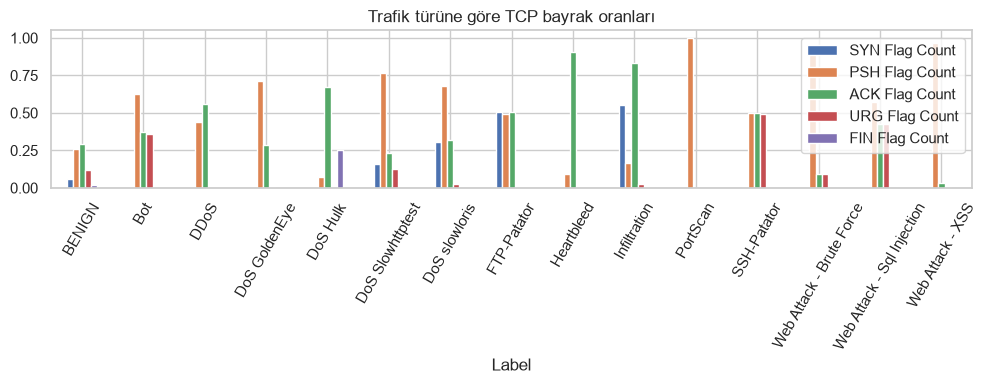

In [3]:
top_ports = df.groupby("Label")["Destination Port"].agg(lambda s: s.value_counts().index[0])
print("Her trafik türünde en sık hedef port:\n", top_ports.to_string())
fig, ax = plt.subplots(figsize=(10, 4))
(df.groupby("Label")[["SYN Flag Count", "PSH Flag Count", "ACK Flag Count", "URG Flag Count", "FIN Flag Count"]].mean()
   .plot.bar(ax=ax)); ax.set_title("Trafik türüne göre TCP bayrak oranları"); ax.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG / "flags_by_label.png", dpi=120); plt.show()

**Gözlemler:** Saldırı türleri hedef port (21 FTP, 22 SSH, 80 HTTP, 8080 …) ve bayrak profilleriyle belirgin şekilde ayrışıyor.
Akış süresi, paket sayıları ve byte hızları ise çok geniş ve çarpık aralıklarda → kurala girebilmeleri için **ayrık kategorilere** dönüştürülmeleri gerekir.

## 3. Veri Hazırlama (Data Preparation)
- **Port:** bilinen servis portları isimlendirilir (`port=HTTP(80)`), diğerleri "well-known / registered / dynamic" aralıklarına ayrılır.
- **Sayısal öznitelikler:** eşit frekanslı (quantile) aralıklara bölünür. Aralık sayısı (`n_bins`) AutoML tarafından da optimize edilen bir parametredir.
- **Bayraklar:** `SYN=1` / `SYN=0` gibi ikili öğeler.
- Her akış, bu öğelerden oluşan bir **işlem (transaction)** olur; etiket `attack=…` öğesi olarak eklenir.

In [4]:
SERVICES = {21: "FTP", 22: "SSH", 80: "HTTP", 443: "HTTPS", 53: "DNS", 8080: "HTTP-ALT", 139: "NetBIOS", 445: "SMB", 444: "444"}
NUMERIC = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Bytes/s", "Packet Length Mean", "Init_Win_bytes_forward"]
FLAGS = ["FIN Flag Count", "SYN Flag Count", "RST Flag Count", "PSH Flag Count", "ACK Flag Count", "URG Flag Count"]
SHORT = {"Flow Duration": "duration", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
         "Flow Bytes/s": "bytes_per_s", "Packet Length Mean": "pkt_len", "Init_Win_bytes_forward": "init_win"}


def port_item(p):
    if p in SERVICES:
        return f"port={SERVICES[p]}({p})"
    return "port=well-known(<1024)" if p < 1024 else ("port=registered(1024-49151)" if p < 49152 else "port=dynamic(>=49152)")


def to_transactions(data: pd.DataFrame, n_bins: int = 4):
    names = {3: ["low", "mid", "high"], 4: ["very_low", "low", "high", "very_high"],
             5: ["very_low", "low", "mid", "high", "very_high"], 6: [f"q{i}" for i in range(1, 7)]}[n_bins]
    items = pd.DataFrame(index=data.index)
    items["port"] = data["Destination Port"].map(port_item)
    for c in NUMERIC:
        binned = pd.qcut(data[c].rank(method="first"), q=n_bins, labels=names[:n_bins])
        items[c] = SHORT[c] + "=" + binned.astype(str)
    for c in FLAGS:
        items[c] = c.split()[0] + "=" + (data[c] > 0).astype(int).astype(str)
    items["label"] = "attack=" + data["Label"]
    return items.values.tolist()


transactions = to_transactions(df, n_bins=4)
te = TransactionEncoder()
basket = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("İşlem sayısı:", basket.shape[0], "| Farklı öğe sayısı:", basket.shape[1])
print("Örnek işlem:", transactions[0])

İşlem sayısı: 39183 | Farklı öğe sayısı: 63
Örnek işlem: ['port=HTTP-ALT(8080)', 'duration=high', 'fwd_pkts=low', 'bwd_pkts=high', 'bytes_per_s=low', 'pkt_len=low', 'init_win=high', 'FIN=0', 'SYN=0', 'RST=0', 'PSH=1', 'ACK=0', 'URG=0', 'attack=Bot']


## 4. Modelleme (Modeling)
### 4.1 Apriori ve FP-Growth karşılaştırması
İki algoritma aynı sık öğe kümelerini bulur; fark **hız ve bellek** kullanımındadır.

In [5]:
MIN_SUP = 0.01
timing = []
for name, algo in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
    t0 = time.perf_counter()
    fi = algo(basket, min_support=MIN_SUP, use_colnames=True, max_len=5)
    timing.append({"Algoritma": name, "Süre (sn)": round(time.perf_counter() - t0, 2), "Sık öğe kümesi": len(fi)})
pd.DataFrame(timing)

,Algoritma,Süre (sn),Sık öğe kümesi
0,Apriori,68.03,84136
1,FP-Growth,2.18,84136


In [6]:
def mine_rules(basket, min_support, min_confidence, min_lift=1.2, max_len=5):
    fi = fpgrowth(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    if fi.empty:
        return pd.DataFrame()
    rules = association_rules(fi, metric="confidence", min_threshold=min_confidence)
    # Yalnızca sonucu tek bir 'attack=' öğesi olan kurallar (saldırı imzası) ve öncülünde etiket olmayanlar
    rules = rules[rules["consequents"].apply(lambda s: len(s) == 1 and next(iter(s)).startswith("attack="))]
    rules = rules[rules["antecedents"].apply(lambda s: not any(i.startswith("attack=") for i in s))]
    rules = rules[rules["lift"] >= min_lift]
    return prune(rules)


def prune(rules: pd.DataFrame) -> pd.DataFrame:
    """Gereksiz kuralları buda: aynı sonuca sahip, öncülü daha kısa ve confidence'ı en az aynı olan bir kural varsa uzun olanı at."""
    if rules.empty:
        return rules
    rules = rules.sort_values(["confidence", "support"], ascending=False).head(3000).reset_index(drop=True)
    keep = []
    for i, r in rules.iterrows():
        redundant = any(k["consequents"] == r["consequents"] and k["antecedents"] < r["antecedents"]
                        and k["confidence"] >= r["confidence"] - 1e-9 for k in keep)
        if not redundant:
            keep.append(r)
    return pd.DataFrame(keep).reset_index(drop=True)


rules = mine_rules(basket, min_support=MIN_SUP, min_confidence=0.8)
print("Budama sonrası kural sayısı:", len(rules))
show = rules.assign(Öncül=rules["antecedents"].apply(lambda s: " & ".join(sorted(s))),
                    Sonuç=rules["consequents"].apply(lambda s: next(iter(s))))
show[["Öncül", "Sonuç", "support", "confidence", "lift"]].head(15).round(3)

Budama sonrası kural sayısı: 337


,Öncül,Sonuç,support,confidence,lift
0,ACK=0 & FIN=0 & init_win=very_low,attack=BENIGN,0.167,1.0,2.612
1,ACK=0 & FIN=0 & PSH=0,attack=BENIGN,0.167,1.0,2.612
2,init_win=very_low & port=DNS(53),attack=BENIGN,0.160,1.0,2.612
3,PSH=0 & port=DNS(53),attack=BENIGN,0.160,1.0,2.612
4,URG=0 & init_win=very_low & pkt_len=high,attack=BENIGN,0.159,1.0,2.612
5,ACK=0 & PSH=0 & pkt_len=high,attack=BENIGN,0.158,1.0,2.612
6,ACK=0 & init_win=very_low & pkt_len=high,attack=BENIGN,0.158,1.0,2.612
7,pkt_len=high & port=DNS(53),attack=BENIGN,0.152,1.0,2.612
8,duration=low & port=DNS(53),attack=BENIGN,0.129,1.0,2.612
9,PSH=0 & URG=0 & duration=low & pkt_len=high,attack=BENIGN,0.127,1.0,2.612


### 4.2 AutoML — Genetik Algoritma ile parametre optimizasyonu

Birliktelik analizinde "model" kalitesini belirleyen şey **eşik ve ön işleme parametreleridir**: `min_support`, `min_confidence`, `min_lift`,
kural uzunluğu (`max_len`) ve ayrıklaştırma aralık sayısı (`n_bins`). Bu parametreler **Genetik Algoritma (NSGA-II)** ile optimize edilir.

**Amaç fonksiyonu (maksimize):** `kapsanan saldırı türü oranı × ortalama confidence × log(1 + ortalama lift)` − kural sayısı cezası.
Böylece az sayıda, kesinliği yüksek ve çok sayıda saldırı türünü açıklayan bir kural kümesi aranır.

In [7]:
attack_types = sorted(l for l in df["Label"].unique() if l != "BENIGN")
basket_cache = {}


def get_basket(n_bins):
    if n_bins not in basket_cache:
        t = to_transactions(df, n_bins)
        e = TransactionEncoder()
        basket_cache[n_bins] = pd.DataFrame(e.fit(t).transform(t), columns=e.columns_)
    return basket_cache[n_bins]


def rule_quality(r):
    if r.empty:
        return 0.0, 0.0
    attacks = {next(iter(c))[7:] for c in r["consequents"]} - {"BENIGN"}
    coverage = len(attacks) / len(attack_types)
    score = coverage * r["confidence"].mean() * np.log1p(r["lift"].mean()) - 0.001 * max(0, len(r) - 60)
    return score, coverage


def objective(trial):
    p = dict(n_bins=trial.suggest_int("n_bins", 3, 6),
             min_support=trial.suggest_float("min_support", 0.002, 0.05, log=True),
             min_confidence=trial.suggest_float("min_confidence", 0.6, 0.99),
             min_lift=trial.suggest_float("min_lift", 1.0, 5.0),
             max_len=trial.suggest_int("max_len", 2, 5))
    r = mine_rules(get_basket(p.pop("n_bins")), **p)
    score, coverage = rule_quality(r)
    trial.set_user_attr("n_rules", len(r)); trial.set_user_attr("coverage", coverage)
    return score


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.NSGAIISampler(population_size=10, seed=SEED))
study.optimize(objective, n_trials=40)
print("En iyi skor:", round(study.best_value, 4), "| Parametreler:", study.best_params)
print("Kural sayısı:", study.best_trial.user_attrs["n_rules"], "| Kapsanan saldırı türü oranı:", round(study.best_trial.user_attrs["coverage"], 3))

En iyi skor: 1.512 | Parametreler: {'n_bins': 5, 'min_support': 0.0031335313528540578, 'min_confidence': 0.8005514309813085, 'min_lift': 3.36965827544817, 'max_len': 3}
Kural sayısı: 75 | Kapsanan saldırı türü oranı: 0.571


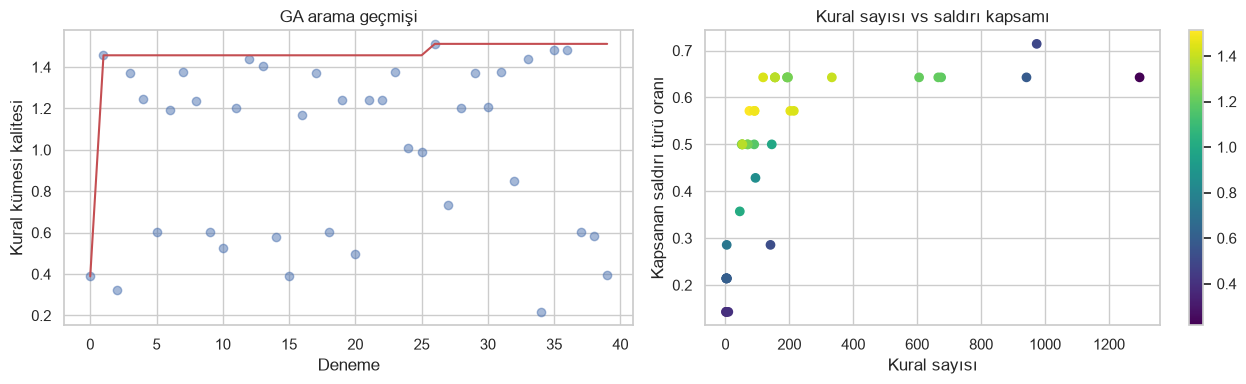

In [8]:
hist = study.trials_dataframe()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist["number"], hist["value"], "o", alpha=.5); ax[0].plot(hist["number"], hist["value"].cummax(), "r-")
ax[0].set(title="GA arama geçmişi", xlabel="Deneme", ylabel="Kural kümesi kalitesi")
sc = ax[1].scatter(hist["user_attrs_n_rules"], hist["user_attrs_coverage"], c=hist["value"], cmap="viridis")
ax[1].set(title="Kural sayısı vs saldırı kapsamı", xlabel="Kural sayısı", ylabel="Kapsanan saldırı türü oranı"); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.savefig(FIG / "automl_history.png", dpi=120); plt.show()

## 5. Değerlendirme (Evaluation)

In [9]:
bp = dict(study.best_params)
best_basket = get_basket(bp.pop("n_bins"))
best_rules = mine_rules(best_basket, **bp)
best_rules["Öncül"] = best_rules["antecedents"].apply(lambda s: " & ".join(sorted(s)))
best_rules["Sonuç"] = best_rules["consequents"].apply(lambda s: next(iter(s))[7:])
best_rules = best_rules.sort_values(["Sonuç", "confidence"], ascending=[True, False])
cols = ["Öncül", "Sonuç", "support", "confidence", "lift"]
best_rules[cols].to_csv(OUT / "attack_rules.csv", index=False)
# Her saldırı türü için en güçlü kural
best_rules.groupby("Sonuç").head(1)[cols].round(3).reset_index(drop=True)

,Öncül,Sonuç,support,confidence,lift
0,bytes_per_s=mid & port=HTTP-ALT(8080),Bot,0.003,1.000,20.032
1,fwd_pkts=mid & pkt_len=very_high,DDoS,0.025,0.811,12.704
2,FIN=1 & duration=very_high,DoS Hulk,0.014,1.000,15.673
3,bytes_per_s=very_low & fwd_pkts=high,DoS Slowhttptest,0.030,0.871,13.644
4,SYN=1 & pkt_len=low,DoS slowloris,0.019,0.866,13.576
5,SYN=1 & port=FTP(21),FTP-Patator,0.032,1.000,15.673
6,PSH=1 & fwd_pkts=very_low,PortScan,0.057,0.994,15.576
7,bytes_per_s=mid & port=SSH(22),SSH-Patator,0.032,0.999,15.661


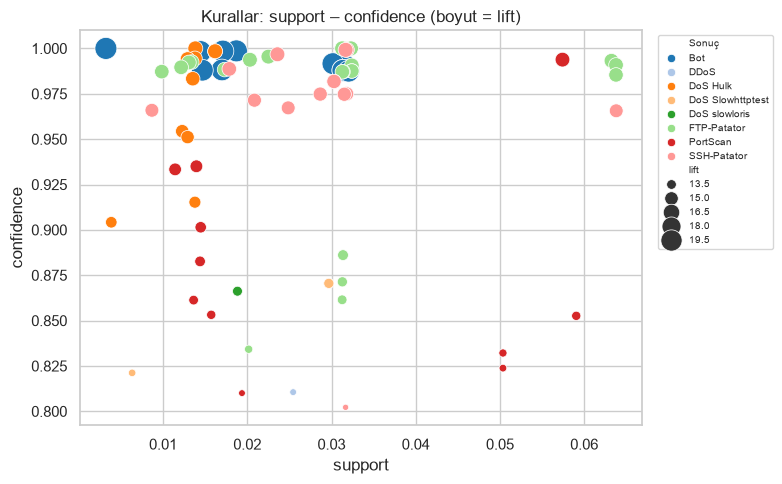

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=best_rules, x="support", y="confidence", hue="Sonuç", size="lift", sizes=(20, 250), ax=ax, palette="tab20")
ax.set_title("Kurallar: support – confidence (boyut = lift)"); ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "rules_scatter.png", dpi=120); plt.show()

In [11]:
# Kuralların ayırt edicilik testi: her akışa, öncülünü sağlayan en yüksek confidence'lı kuralın sonucu atanır.
items_sets = [frozenset(t) for t in to_transactions(df, study.best_params["n_bins"])]
ordered = best_rules.sort_values("confidence", ascending=False)[["antecedents", "Sonuç"]].values.tolist()
pred = []
for s in items_sets:
    match = next((c for a, c in ordered if a <= s), None)
    pred.append(match)
pred = pd.Series(pred, index=df.index)
covered = pred.notna()
acc = (pred[covered] == df.loc[covered, "Label"]).mean()
print(f"Kuralların kapsadığı akış oranı: {covered.mean():.3f} | Kapsanan akışlarda doğruluk: {acc:.3f}")
print((pred[covered] == df.loc[covered, "Label"]).groupby(df.loc[covered, "Label"]).mean().round(3).to_string())

Kuralların kapsadığı akış oranı: 0.377 | Kapsanan akışlarda doğruluk: 0.848
Label
BENIGN                      0.000
Bot                         1.000
DDoS                        0.917
DoS Hulk                    0.773
DoS Slowhttptest            0.900
DoS slowloris               0.906
FTP-Patator                 1.000
Infiltration                0.000
PortScan                    0.996
SSH-Patator                 1.000
Web Attack - Brute Force    0.000
Web Attack - XSS            0.000


## 6. Dağıtım (Deployment) ve Sonuç
- Bulunan kurallar `results/attack_rules.csv` dosyasına yazıldı; her satır doğrudan bir IDS imzası taslağıdır
  (ör. `port=FTP(21) & init_win=… → FTP-Patator`).
- Port, bayrak ve akış hacmi öğeleri saldırı türlerinin çoğunu **yüksek confidence ve yüksek lift** ile tanımlamaktadır; DoS varyantları ve brute-force saldırıları en net
  kurallara sahiptir. Örnek sayısı çok az olan türler (Heartbleed, Infiltration, SQL Injection) seyrek veri nedeniyle `min_support` eşiğinin altında kalır — bu, birliktelik
  analizinin bilinen bir sınırıdır.
- Genetik algoritma, elle seçilen eşiklere göre daha az ama daha fazla saldırı türünü kapsayan bir kural kümesi buldu.
- **Sonraki adımlar:** Gerçek bir CTI beslemesi (IP itibarı, ASN, domain, malware hash) ile aynı akışın uygulanması; kuralların zaman içinde geçerliliğini yitirip yitirmediğinin (concept drift) izlenmesi.